# Binance — Dataset de Trading (OHLCV)

Notebook **unificado** (reemplaza a `Binance_API___Peticiones_REST___Velas_japonesas` y a `binance_dataset_VELAS`).
Está centrado en una sola cosa: **construir, revisar, exportar y visualizar un dataset de velas (klines)** como base para un dataset de trading.

Usa solo endpoints públicos de Binance (market data): **no necesita API key**. Listo para Google Colab.

| # | Sección | Qué hace |
|---|---------|----------|
| 1 | Dependencias | Instala e importa librerías |
| 2 | Parámetros | Único lugar que necesitas editar (símbolo, intervalo, fechas, exportación, gráficos) |
| 3 | Funciones de API | Requests con reintentos, selección automática de URL y descarga paginada |
| 4 | Descarga | Baja el histórico de velas |
| 5 | DataFrame y limpieza | Tipos correctos, UTC, duplicados, vela incompleta |
| 6 | Control de calidad | Huecos, nulos, OHLC inconsistente, volumen 0 |
| 7 | Vista del DataFrame | `info`, `head`, `tail`, `describe` |
| 8 | Exportar | CSV y Excel (con descarga directa en Colab) |
| 9 | Gráficos básicos | Línea de cierre, velas + volumen (interactivos) y velas estáticas |
| 10 | Features / indicadores | Retornos, medias móviles, RSI, MACD, Bollinger, ATR, volumen… |
| 11 | Gráficos con indicadores | Dashboard de velas + RSI + MACD, retornos, volatilidad, drawdown, heatmap mensual |
| 12 | Target + split temporal | Variable a predecir, partición train/val/test sin mezclar fechas, correlaciones |
| 13 | Exportar dataset de trading | CSV y Excel con features, target y split |
| A | Apéndice (opcional) | Exploración de la API: ping, hora, exchangeInfo, order book, trades, ticker |

## 1. Dependencias

In [1]:
# En Colab ya vienen pandas, requests y plotly; mplfinance suele faltar.
!pip install -q mplfinance openpyxl plotly tqdm

import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import mplfinance as mpf
from IPython.display import display
from tqdm.auto import tqdm

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

## 2. Parámetros

Todo lo configurable está en esta celda. Para otro par, temporalidad o rango de fechas, cambia los valores y vuelve a ejecutar el notebook desde aquí.

**Sobre la fuente de datos (`BASE_URL`):** en `"auto"` el notebook prueba cada URL de `BASE_URL_CANDIDATES` y usa la primera que responda.
Binance.com bloquea algunas regiones/IPs con error 451 (por ejemplo, a veces en Colab). `data-api.binance.vision` es el endpoint oficial solo de market data y suele funcionar.
**Binance.US es otro exchange** (distinto histórico, precios y volúmenes), por eso queda de último recurso y el notebook avisa si termina usándolo.

In [2]:
# ============================== PARÁMETROS ==============================

# --- Qué descargar ----------------------------------------------------------
SYMBOL     = "BTCUSDT"     # Ej: "BTCUSDT", "ETHUSDT", "SOLUSDT"
INTERVAL   = "1d"          # "1m","3m","5m","15m","30m","1h","2h","4h","6h","8h","12h","1d","3d","1w","1M"
START_DATE = "2017-01-01"  # UTC "YYYY-MM-DD". Si el par aún no existía, Binance devuelve desde su primera vela.
END_DATE   = None          # UTC "YYYY-MM-DD" (incluye ese día completo). None = hasta ahora.

# --- De dónde descargar -----------------------------------------------------
BASE_URL = "auto"          # "auto" o una URL fija, ej: "https://api.binance.com/api/v3"
BASE_URL_CANDIDATES = [
    "https://data-api.binance.vision/api/v3",  # Binance.com, solo market data
    "https://api.binance.com/api/v3",          # Binance.com
]

# --- Descarga ---------------------------------------------------------------
LIMIT_PER_REQUEST     = 1000   # Máximo permitido por Binance en /klines
REQUEST_SLEEP_SECONDS = 0.3    # Pausa entre requests (evita rate limits)

# --- Exportación ------------------------------------------------------------
OUTPUT_DIR    = "datasets"
EXPORT_CSV    = True
EXPORT_EXCEL  = True
AUTO_DOWNLOAD = True           # En Colab: descarga cada archivo a tu computador al exportarlo
SAVE_CHARTS_HTML = False       # True = guarda además cada gráfico interactivo como .html

# --- Gráficos ---------------------------------------------------------------
PLOT_LAST_N_CANDLES = 500      # Velas recientes a graficar en los gráficos de precio. None = todas
PLOT_TEMPLATE = "plotly_dark"  # o "plotly_white"
COLOR_UP, COLOR_DOWN = "#26a69a", "#ef5350"
PLOTLY_CONFIG = {"scrollZoom": True, "displaylogo": False}  # rueda del mouse = zoom

# --- Dataset de trading (secciones 10 a 13) ---------------------------------
TARGET_HORIZON = 1             # El target mira N velas hacia adelante
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15   # El resto (0.15) es test. Partición cronológica, sin mezclar.

# ------------------------------------------------------------------------------
# Validaciones (no hace falta editar de aquí hacia abajo)
# ------------------------------------------------------------------------------
SYMBOL = SYMBOL.upper().strip()

INTERVAL_MS = {
    "1m": 60_000, "3m": 180_000, "5m": 300_000, "15m": 900_000, "30m": 1_800_000,
    "1h": 3_600_000, "2h": 7_200_000, "4h": 14_400_000, "6h": 21_600_000,
    "8h": 28_800_000, "12h": 43_200_000,
    "1d": 86_400_000, "3d": 259_200_000, "1w": 604_800_000,
    "1M": 2_629_800_000,   # ≈ 30,44 días: los meses no tienen duración fija
}
if INTERVAL not in INTERVAL_MS:
    raise ValueError(f"INTERVAL='{INTERVAL}' no es válido. Opciones: {list(INTERVAL_MS)}")
if not 0 < TRAIN_FRAC < 1 or not 0 <= VAL_FRAC < 1 or TRAIN_FRAC + VAL_FRAC >= 1:
    raise ValueError("TRAIN_FRAC y VAL_FRAC deben sumar menos de 1 (el resto es test).")

print(f"Símbolo: {SYMBOL} | Intervalo: {INTERVAL} | Desde: {START_DATE} | Hasta: {END_DATE or 'ahora'}")

Símbolo: BTCUSDT | Intervalo: 1d | Desde: 2017-01-01 | Hasta: ahora


## 3. Funciones de API

- `api_get`: GET genérico con reintentos ante rate limit (HTTP 429/418), timeouts y errores de red; si Binance responde con un error, muestra su mensaje.
- `resolve_base_url`: elige la URL que funcione desde tu ubicación.
- `download_klines`: Binance entrega máximo 1000 velas por request, así que se pagina avanzando `startTime` hasta cubrir el rango pedido.

In [3]:
def now_ms():
    return int(datetime.now(timezone.utc).timestamp() * 1000)


def date_to_ms(date_str):
    """'YYYY-MM-DD' (UTC) -> milisegundos."""
    dt = datetime.strptime(date_str, "%Y-%m-%d").replace(tzinfo=timezone.utc)
    return int(dt.timestamp() * 1000)


def resolve_base_url(base_url=BASE_URL, candidates=BASE_URL_CANDIDATES):
    """Devuelve BASE_URL si es fija; si es 'auto', la primera URL candidata que responda /ping."""
    if base_url != "auto":
        return base_url
    errors = []
    for url in candidates:
        try:
            r = requests.get(f"{url}/ping", timeout=10)
            if r.status_code == 200:
                return url
            errors.append(f"{url} -> HTTP {r.status_code}")
        except requests.RequestException as e:
            errors.append(f"{url} -> {type(e).__name__}")
    raise RuntimeError(
        "Ninguna URL de Binance respondió:\n  " + "\n  ".join(errors) +
        "\nHTTP 451/403 = bloqueo por región: prueba otra ubicación/VPN o ejecuta el notebook en tu PC."
    )


def api_get(endpoint, params=None, base_url=None, max_retries=5, timeout=15):
    """GET a la API de Binance con reintentos. Devuelve el JSON de la respuesta."""
    url = f"{base_url}/{endpoint}"
    for attempt in range(1, max_retries + 1):
        try:
            r = requests.get(url, params=params, timeout=timeout)
        except (requests.ConnectionError, requests.Timeout) as e:
            wait = 2 ** attempt
            tqdm.write(f"  Error de red ({type(e).__name__}). Reintento en {wait}s ({attempt}/{max_retries})...")
            time.sleep(wait)
            continue

        if r.status_code == 200:
            return r.json()

        if r.status_code in (429, 418):   # rate limit / IP baneada temporalmente
            wait = int(r.headers.get("Retry-After", 2 ** attempt))
            tqdm.write(f"  Rate limit (HTTP {r.status_code}). Esperando {wait}s ({attempt}/{max_retries})...")
            time.sleep(wait)
            continue

        try:
            detail = r.json()             # Binance: {"code": -1121, "msg": "Invalid symbol."}
        except ValueError:
            detail = r.text[:200]
        raise RuntimeError(f"HTTP {r.status_code} en '{endpoint}': {detail}")

    raise RuntimeError(f"No se pudo completar '{endpoint}' tras {max_retries} reintentos.")


def download_klines(symbol, interval, start_date, end_date=None, base_url=None,
                    limit=LIMIT_PER_REQUEST, sleep_seconds=REQUEST_SLEEP_SECONDS):
    """Descarga todas las velas entre start_date y end_date (incluido) con paginación.

    Devuelve la lista cruda de klines (cada vela = lista de 12 valores).
    """
    start_ms = date_to_ms(start_date)
    # END_DATE incluye el día completo
    end_ms = date_to_ms(end_date) + 86_400_000 - 1 if end_date else now_ms()

    est_requests = max(1, (end_ms - start_ms) // INTERVAL_MS[interval] // limit + 1)
    all_klines, cursor = [], start_ms

    with tqdm(total=est_requests, desc=f"{symbol} {interval}", unit="req") as pbar:
        while cursor < end_ms:
            batch = api_get(
                "klines",
                {"symbol": symbol, "interval": interval, "startTime": cursor,
                 "endTime": end_ms, "limit": limit},
                base_url=base_url,
            )
            if not batch:
                break

            all_klines.extend(batch)
            pbar.update(1)
            pbar.set_postfix(velas=f"{len(all_klines):,}")

            next_cursor = batch[-1][6] + 1          # close_time + 1 ms
            if next_cursor <= cursor:               # salvaguarda anti loop infinito
                break
            cursor = next_cursor

            if len(batch) < limit:                  # ya no hay más datos
                break
            time.sleep(sleep_seconds)

    return all_klines

## 4. Descarga del histórico

Antes de descargar se muestra una estimación **máxima** (si el par existe desde `START_DATE`; los pares nuevos tienen menos historia).

In [4]:
BASE_URL_USED = resolve_base_url()
print(f"Fuente de datos: {BASE_URL_USED}")
if "binance.us" in BASE_URL_USED:
    print("AVISO: estás usando Binance.US, que es OTRO exchange (menos histórico y otros volúmenes que Binance.com).")

# Estimación (máxima) del trabajo
_start = date_to_ms(START_DATE)
_end = date_to_ms(END_DATE) + 86_400_000 - 1 if END_DATE else now_ms()
est_candles = (_end - _start) // INTERVAL_MS[INTERVAL]
est_requests = est_candles // LIMIT_PER_REQUEST + 1
print(f"Estimado (máx.): ~{est_candles:,} velas en ~{est_requests:,} requests "
      f"(~{est_requests * REQUEST_SLEEP_SECONDS / 60:.1f} min de pausas)")
if est_candles > 1_000_000:
    print("AVISO: más de 1 millón de velas. Excel admite máx. 1.048.575 filas (se omitirá el .xlsx) "
          "y los gráficos serán pesados: considera un intervalo mayor o un rango más corto.")

raw_klines = download_klines(SYMBOL, INTERVAL, START_DATE, END_DATE, base_url=BASE_URL_USED)
print(f"\nVelas descargadas: {len(raw_klines):,}")

Fuente de datos: https://data-api.binance.vision/api/v3
Estimado (máx.): ~3,596 velas en ~4 requests (~0.0 min de pausas)


BTCUSDT 1d:   0%|          | 0/4 [00:00<?, ?req/s]


Velas descargadas: 3,369


## 5. DataFrame y limpieza

- Columnas numéricas a `float`, `number_of_trades` a `int`.
- `open_time` y `close_time` a `datetime` en **UTC**.
- Se elimina la columna `ignore`, los duplicados y se ordena cronológicamente.
- Se descarta la última vela si **todavía no cerró** (si no, el dataset tendría un dato "a medias").
- Se agregan `symbol` e `interval` (útil si más adelante juntas varios pares en un solo dataset).

In [5]:
KLINE_COLUMNS = [
    "open_time", "open", "high", "low", "close", "volume",
    "close_time", "quote_asset_volume", "number_of_trades",
    "taker_buy_base", "taker_buy_quote", "ignore",
]
NUM_COLS = ["open", "high", "low", "close", "volume",
            "quote_asset_volume", "taker_buy_base", "taker_buy_quote"]


def build_dataframe(raw, symbol, interval):
    """Convierte la lista cruda de klines en un DataFrame limpio y tipado."""
    if not raw:
        raise ValueError("Binance no devolvió velas. Revisa SYMBOL, INTERVAL y el rango de fechas.")

    df = pd.DataFrame(raw, columns=KLINE_COLUMNS)
    df[NUM_COLS] = df[NUM_COLS].astype(float)
    df["number_of_trades"] = df["number_of_trades"].astype(int)
    df["open_time"] = pd.to_datetime(df["open_time"], unit="ms", utc=True)
    df["close_time"] = pd.to_datetime(df["close_time"], unit="ms", utc=True)
    df = df.drop(columns=["ignore"])

    n_before = len(df)
    df = df.drop_duplicates(subset="open_time").sort_values("open_time").reset_index(drop=True)
    n_dups = n_before - len(df)

    dropped_incomplete = False
    if df.iloc[-1]["close_time"] > pd.Timestamp.now(tz="UTC"):
        df = df.iloc[:-1].reset_index(drop=True)
        dropped_incomplete = True
    if df.empty:
        raise ValueError("No quedaron velas cerradas en el rango pedido.")

    df.insert(0, "symbol", symbol)
    df.insert(1, "interval", interval)
    return df, n_dups, dropped_incomplete


df, n_dups, dropped_incomplete = build_dataframe(raw_klines, SYMBOL, INTERVAL)

# Metadatos del dataset (se guardan en la hoja "info" del Excel)
DATASET_INFO = {
    "symbol": SYMBOL,
    "interval": INTERVAL,
    "fuente_api": BASE_URL_USED,
    "primera_vela_utc": str(df["open_time"].min()),
    "ultima_vela_utc": str(df["open_time"].max()),
    "filas": len(df),
    "duplicados_eliminados": n_dups,
    "ultima_vela_incompleta_descartada": dropped_incomplete,
    "generado_utc": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
}

print(f"Dataset final: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"Rango: {df['open_time'].min()}  →  {df['open_time'].max()}")
print(f"Duplicados eliminados: {n_dups} | Última vela incompleta descartada: {dropped_incomplete}")
df.head()

Dataset final: 3,368 filas x 13 columnas
Rango: 2017-08-17 00:00:00+00:00  →  2026-11-05 00:00:00+00:00
Duplicados eliminados: 0 | Última vela incompleta descartada: True


,symbol,interval,open_time,open,high,low,close,volume,close_time,quote_asset_volume,number_of_trades,taker_buy_base,taker_buy_quote
0,BTCUSDT,1d,2017-08-17 00:00:00+00:00,4261.48,4485.39,4200.74,4285.08,795.150377,2017-08-17 23:59:59.999000+00:00,3.454770e+06,3427,616.248541,2.678216e+06
1,BTCUSDT,1d,2017-08-18 00:00:00+00:00,4285.08,4371.52,3938.77,4108.37,1199.888264,2017-08-18 23:59:59.999000+00:00,5.086958e+06,5233,972.868710,4.129123e+06
2,BTCUSDT,1d,2017-08-19 00:00:00+00:00,4108.37,4184.69,3850.00,4139.98,381.309763,2017-08-19 23:59:59.999000+00:00,1.549484e+06,2153,274.336042,1.118002e+06
3,BTCUSDT,1d,2017-08-20 00:00:00+00:00,4120.98,4211.08,4032.62,4086.29,467.083022,2017-08-20 23:59:59.999000+00:00,1.930364e+06,2321,376.795947,1.557401e+06
4,BTCUSDT,1d,2017-08-21 00:00:00+00:00,4069.13,4119.62,3911.79,4016.00,691.743060,2017-08-21 23:59:59.999000+00:00,2.797232e+06,3972,557.356107,2.255663e+06


## 6. Control de calidad

Antes de construir nada sobre estos datos conviene verificar que estén sanos:

- **Huecos temporales:** velas que faltan entre dos fechas (mantenimientos del exchange, por ejemplo).
- **OHLC inconsistente:** `high` menor que `open`/`close`, o `low` mayor que ellos.
- **Precios ≤ 0, nulos y velas con volumen 0.**

In [6]:
def quality_report(df, interval):
    """Devuelve (tabla_de_chequeos, tabla_de_huecos)."""
    o, h, l, c = df["open"], df["high"], df["low"], df["close"]

    ohlc_bad = (h < pd.concat([o, c, l], axis=1).max(axis=1)) | (l > pd.concat([o, c, h], axis=1).min(axis=1))

    gaps = pd.DataFrame(columns=["desde", "hasta", "velas_faltantes"])
    gap_note = ""
    if interval == "1M":
        gap_note = "no aplica (los meses no tienen duración fija)"
    else:
        step = pd.Timedelta(milliseconds=INTERVAL_MS[interval])
        diffs = df["open_time"].diff()
        mask = diffs > step
        gaps = pd.DataFrame({
            "desde": (df["open_time"].shift(1) + step)[mask],
            "hasta": (df["open_time"] - step)[mask],
            "velas_faltantes": (diffs[mask] / step).round().astype(int) - 1,
        }).reset_index(drop=True)

    def row(nombre, valor, ok):
        return {"chequeo": nombre, "resultado": str(valor), "estado": "OK" if ok else "REVISAR"}

    n_missing = int(gaps["velas_faltantes"].sum()) if len(gaps) else 0
    checks = pd.DataFrame([
        row("Filas", f"{len(df):,}", True),
        row("Orden cronológico", df["open_time"].is_monotonic_increasing, df["open_time"].is_monotonic_increasing),
        row("Valores nulos (total)", int(df.isna().sum().sum()), df.isna().sum().sum() == 0),
        row("Precios <= 0", int((df[["open", "high", "low", "close"]] <= 0).sum().sum()),
            (df[["open", "high", "low", "close"]] <= 0).sum().sum() == 0),
        row("Velas con OHLC inconsistente", int(ohlc_bad.sum()), ohlc_bad.sum() == 0),
        row("Velas con volumen 0", int((df["volume"] == 0).sum()), (df["volume"] == 0).sum() == 0),
        row("Huecos temporales", f"{len(gaps)} huecos / {n_missing} velas faltantes" if not gap_note else gap_note,
            len(gaps) == 0),
    ])
    return checks, gaps


quality_checks, quality_gaps = quality_report(df, INTERVAL)
display(quality_checks)

if len(quality_gaps):
    print("\nMayores huecos detectados:")
    display(quality_gaps.sort_values("velas_faltantes", ascending=False).head(10))

,chequeo,resultado,estado
0,Filas,"3,368",OK
1,Orden cronológico,True,OK
2,Valores nulos (total),0,OK
3,Precios <= 0,0,OK
4,Velas con OHLC inconsistente,0,OK
5,Velas con volumen 0,0,OK
6,Huecos temporales,0 huecos / 0 velas faltantes,OK


## 7. Vista del DataFrame

In [7]:
print(f"Shape: {df.shape}\n")
df.info()

print("\nPrimeras filas:")
display(df.head())

print("\nÚltimas filas:")
display(df.tail())

print("\nEstadísticas descriptivas:")
display(df.describe().T)

Shape: (3368, 13)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3368 entries, 0 to 3367
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype              
---  ------              --------------  -----              
 0   symbol              3368 non-null   object             
 1   interval            3368 non-null   object             
 2   open_time           3368 non-null   datetime64[ns, UTC]
 3   open                3368 non-null   float64            
 4   high                3368 non-null   float64            
 5   low                 3368 non-null   float64            
 6   close               3368 non-null   float64            
 7   volume              3368 non-null   float64            
 8   close_time          3368 non-null   datetime64[ns, UTC]
 9   quote_asset_volume  3368 non-null   float64            
 10  number_of_trades    3368 non-null   int64              
 11  taker_buy_base      3368 non-null   float64            
 12  taker_buy_quote

,symbol,interval,open_time,open,high,low,close,volume,close_time,quote_asset_volume,number_of_trades,taker_buy_base,taker_buy_quote
0,BTCUSDT,1d,2017-08-17 00:00:00+00:00,4261.48,4485.39,4200.74,4285.08,795.150377,2017-08-17 23:59:59.999000+00:00,3.454770e+06,3427,616.248541,2.678216e+06
1,BTCUSDT,1d,2017-08-18 00:00:00+00:00,4285.08,4371.52,3938.77,4108.37,1199.888264,2017-08-18 23:59:59.999000+00:00,5.086958e+06,5233,972.868710,4.129123e+06
2,BTCUSDT,1d,2017-08-19 00:00:00+00:00,4108.37,4184.69,3850.00,4139.98,381.309763,2017-08-19 23:59:59.999000+00:00,1.549484e+06,2153,274.336042,1.118002e+06
3,BTCUSDT,1d,2017-08-20 00:00:00+00:00,4120.98,4211.08,4032.62,4086.29,467.083022,2017-08-20 23:59:59.999000+00:00,1.930364e+06,2321,376.795947,1.557401e+06
4,BTCUSDT,1d,2017-08-21 00:00:00+00:00,4069.13,4119.62,3911.79,4016.00,691.743060,2017-08-21 23:59:59.999000+00:00,2.797232e+06,3972,557.356107,2.255663e+06



Últimas filas:


,symbol,interval,open_time,open,high,low,close,volume,close_time,quote_asset_volume,number_of_trades,taker_buy_base,taker_buy_quote
3363,BTCUSDT,1d,2026-11-01 00:00:00+00:00,77582.02,78422.23,77517.20,78354.00,6544.36057,2026-11-01 23:59:59.999000+00:00,5.101605e+08,1147208,3400.27887,2.650797e+08
3364,BTCUSDT,1d,2026-11-02 00:00:00+00:00,78354.01,78878.01,76705.00,76816.00,12640.71498,2026-11-02 23:59:59.999000+00:00,9.832433e+08,3069431,7081.31172,5.507885e+08
3365,BTCUSDT,1d,2026-11-03 00:00:00+00:00,76816.01,78063.30,76388.88,77453.86,12560.17626,2026-11-03 23:59:59.999000+00:00,9.694144e+08,2723726,6168.77522,4.763865e+08
3366,BTCUSDT,1d,2026-11-04 00:00:00+00:00,77453.85,81196.01,75736.38,80504.01,22140.42854,2026-11-04 23:59:59.999000+00:00,1.747283e+09,4555713,11955.01112,9.442362e+08
3367,BTCUSDT,1d,2026-11-05 00:00:00+00:00,80504.01,80918.01,75208.42,76088.01,26059.74254,2026-11-05 23:59:59.999000+00:00,2.025461e+09,4929786,11649.36680,9.040976e+08



Estadísticas descriptivas:


,count,mean,std,min,25%,50%,75%,max
open,3368.0,3.941172e+04,3.262308e+04,3188.010000,9.511498e+03,2.929545e+04,6.361155e+04,1.246585e+05
high,3368.0,4.021592e+04,3.312737e+04,3276.500000,9.718570e+03,2.983293e+04,6.459350e+04,1.261996e+05
low,3368.0,3.854617e+04,3.208486e+04,2817.000000,9.235958e+03,2.885595e+04,6.245986e+04,1.230840e+05
close,3368.0,3.943309e+04,3.262356e+04,3189.020000,9.516142e+03,2.930777e+04,6.363199e+04,1.246585e+05
volume,3368.0,5.840793e+04,7.444012e+04,228.108068,2.137231e+04,3.650789e+04,6.168472e+04,7.607054e+05
quote_asset_volume,3368.0,1.724267e+09,1.860900e+09,977865.733332,4.224398e+08,1.192943e+09,2.309622e+09,1.746531e+10
number_of_trades,3368.0,2.026631e+06,2.228247e+06,2153.000000,4.709162e+05,1.254675e+06,2.691310e+06,1.536401e+07
taker_buy_base,3368.0,2.900306e+04,3.705459e+04,56.190141,1.062866e+04,1.823316e+04,3.053456e+04,3.747756e+05
taker_buy_quote,3368.0,8.513635e+08,9.241256e+08,241363.800502,2.093914e+08,5.829607e+08,1.139962e+09,8.783916e+09


## 8. Exportar el dataset base (CSV y Excel)

- **CSV:** fechas en ISO con zona UTC. Para volver a cargarlo:
  `pd.read_csv(ruta, parse_dates=["open_time", "close_time"])`
- **Excel:** hoja `data` (con encabezado fijo y filtros) + hoja `info` con los metadatos (fuente, rango, fecha de generación…). Excel no admite fechas con zona horaria, por eso allí las fechas van como **UTC sin zona**. Si hay más de 1.048.575 filas, el `.xlsx` se omite y queda el CSV.
- En **Colab**, con `AUTO_DOWNLOAD = True` cada archivo se descarga a tu computador (el navegador puede pedir permiso para descargas múltiples). Los archivos también quedan en la carpeta `OUTPUT_DIR` del entorno.

In [8]:
from openpyxl.utils import get_column_letter

EXCEL_MAX_ROWS = 1_048_575   # límite de Excel (menos la fila de encabezado)


def download_file(path):
    """En Colab dispara la descarga al navegador; fuera de Colab solo informa la ruta."""
    try:
        from google.colab import files
        files.download(str(path))
    except ImportError:
        print(f"   (fuera de Colab: archivo disponible en {Path(path).resolve()})")


def export_dataset(data, name, info=None):
    """Guarda `data` como CSV y/o Excel en OUTPUT_DIR según EXPORT_CSV / EXPORT_EXCEL."""
    out_dir = Path(OUTPUT_DIR)
    out_dir.mkdir(parents=True, exist_ok=True)
    saved = []

    if EXPORT_CSV:
        p = out_dir / f"{name}.csv"
        data.to_csv(p, index=False)
        saved.append(p)

    if EXPORT_EXCEL:
        if len(data) > EXCEL_MAX_ROWS:
            print(f"AVISO: {len(data):,} filas superan el límite de Excel; se omite el .xlsx (usa el CSV).")
        else:
            p = out_dir / f"{name}.xlsx"
            data_x = data.copy()
            for col in data_x.select_dtypes(include=["datetimetz"]).columns:
                data_x[col] = data_x[col].dt.tz_localize(None)       # Excel no soporta zonas horarias

            with pd.ExcelWriter(p, engine="openpyxl", datetime_format="yyyy-mm-dd hh:mm:ss") as xw:
                data_x.to_excel(xw, sheet_name="data", index=False)
                if info:
                    pd.DataFrame({"campo": list(info.keys()),
                                  "valor": [str(v) for v in info.values()]}).to_excel(xw, sheet_name="info", index=False)

                ws = xw.sheets["data"]
                ws.freeze_panes = "A2"
                ws.auto_filter.ref = ws.dimensions
                for i, col in enumerate(data_x.columns, start=1):
                    is_dt = str(data_x[col].dtype).startswith("datetime")
                    ws.column_dimensions[get_column_letter(i)].width = max(len(str(col)), 19 if is_dt else 12) + 2
                if info:
                    xw.sheets["info"].column_dimensions["A"].width = 36
                    xw.sheets["info"].column_dimensions["B"].width = 70
            saved.append(p)

    for p in saved:
        print(f"Guardado: {p}  ({p.stat().st_size / 1e6:.2f} MB)")
        if AUTO_DOWNLOAD:
            download_file(p)
    return saved


BASE_NAME = f"dataset_{SYMBOL}_{INTERVAL}"
paths_raw = export_dataset(df, BASE_NAME, info=DATASET_INFO)

Guardado: datasets/dataset_BTCUSDT_1d.csv  (0.58 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Guardado: datasets/dataset_BTCUSDT_1d.xlsx  (0.35 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Gráficos básicos

Los gráficos de precio usan las últimas `PLOT_LAST_N_CANDLES` velas (cámbialo en la sección 2; `None` = todas).
Todos los gráficos de Plotly son interactivos: **zoom** con la rueda o arrastrando, **pan**, **doble clic** para volver a la vista original y **tooltip** al pasar el mouse.
Con `SAVE_CHARTS_HTML = True` cada uno se guarda además como `.html` para compartirlo.

In [9]:
def get_plot_df(data, n=PLOT_LAST_N_CANDLES):
    """Últimas n velas (o todas si n=None), indexadas por open_time."""
    data = data.tail(n) if n else data
    return data.set_index("open_time")


def price_decimals(s):
    """Decimales razonables según el nivel de precio (BTC: 2, un token de centavos: 6)."""
    m = float(s.median())
    return 2 if m >= 100 else 4 if m >= 1 else 6


def candle_hovertext(d):
    """Tooltip estilo TradingView para cada vela."""
    dec = price_decimals(d["close"])
    chg = d["close"] - d["open"]
    pct = chg / d["open"] * 100
    return [
        f"<b>{t:%b %d, %Y  %H:%M}</b><br>"
        f"Open    {o:,.{dec}f}<br>High    {h:,.{dec}f}<br>"
        f"Low     {l:,.{dec}f}<br>Close   {c:,.{dec}f}<br>"
        f"Change  {ch:+,.{dec}f} ({p:+.2f}%)"
        for t, o, h, l, c, ch, p in zip(d.index, d["open"], d["high"], d["low"], d["close"], chg, pct)
    ]


RANGE_SELECTOR = dict(
    buttons=[
        dict(count=7,  label="1S",   step="day",   stepmode="backward"),
        dict(count=1,  label="1M",   step="month", stepmode="backward"),
        dict(count=3,  label="3M",   step="month", stepmode="backward"),
        dict(count=6,  label="6M",   step="month", stepmode="backward"),
        dict(count=1,  label="YTD",  step="year",  stepmode="todate"),
        dict(count=1,  label="1A",   step="year",  stepmode="backward"),
        dict(step="all", label="Todo"),
    ],
    bgcolor="#2a2e39" if PLOT_TEMPLATE == "plotly_dark" else "#eeeeee",
)


def show_fig(fig, name):
    """Muestra el gráfico y, si SAVE_CHARTS_HTML=True, lo guarda como .html."""
    fig.show(config=PLOTLY_CONFIG)
    if SAVE_CHARTS_HTML:
        out_dir = Path(OUTPUT_DIR)
        out_dir.mkdir(parents=True, exist_ok=True)
        p = out_dir / f"{BASE_NAME}_{name}.html"
        fig.write_html(p, include_plotlyjs="cdn", config=PLOTLY_CONFIG)
        print(f"Gráfico guardado: {p}")
        if AUTO_DOWNLOAD:
            download_file(p)


df_plot = get_plot_df(df)
print(f"Graficando {len(df_plot):,} velas | {df_plot.index.min()}  →  {df_plot.index.max()}")

Graficando 500 velas | 2025-06-24 00:00:00+00:00  →  2026-11-05 00:00:00+00:00


### 9.1 Línea — Precio de cierre

In [10]:
dec = price_decimals(df_plot["close"])

fig_line = go.Figure(
    go.Scatter(
        x=df_plot.index, y=df_plot["close"], mode="lines", name="Close",
        line=dict(color=COLOR_UP, width=1.5),
        hovertemplate="<b>%{x|%b %d, %Y %H:%M}</b><br>Close  %{y:,." + str(dec) + "f}<extra></extra>",
    )
)
fig_line.update_layout(
    title=f"{SYMBOL} — Precio de cierre ({INTERVAL}, {len(df_plot):,} velas)",
    template=PLOT_TEMPLATE, height=480, hovermode="x unified",
    margin=dict(l=40, r=40, t=60, b=40),
)
fig_line.update_xaxes(rangeselector=RANGE_SELECTOR, rangeslider_visible=True)
fig_line.update_yaxes(title_text="Precio (USDT)")

show_fig(fig_line, "close_line")

### 9.2 Velas japonesas + volumen (interactivo)

In [11]:
def plot_candles_volume(d, title):
    fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.03,
                        row_heights=[0.75, 0.25], subplot_titles=(title, "Volumen"))

    fig.add_trace(
        go.Candlestick(
            x=d.index, open=d["open"], high=d["high"], low=d["low"], close=d["close"],
            name="Precio", increasing_line_color=COLOR_UP, decreasing_line_color=COLOR_DOWN,
            hovertext=candle_hovertext(d), hoverinfo="text",
        ), row=1, col=1)

    vol_colors = [COLOR_UP if c >= o else COLOR_DOWN for o, c in zip(d["open"], d["close"])]
    fig.add_trace(
        go.Bar(x=d.index, y=d["volume"], marker_color=vol_colors, name="Volumen", showlegend=False,
               hovertemplate="Vol  %{y:,.2f}<extra></extra>"),
        row=2, col=1)

    fig.update_layout(
        height=720, template=PLOT_TEMPLATE, hovermode="x unified", xaxis_rangeslider_visible=False,
        hoverlabel=dict(bgcolor="#131722", bordercolor="#2a2e39", align="left",
                        font=dict(family="Consolas, Menlo, monospace", size=12, color="#d1d4dc")),
        margin=dict(l=40, r=40, t=60, b=40),
    )
    fig.update_yaxes(title_text="Precio (USDT)", row=1, col=1)
    fig.update_yaxes(title_text="Volumen", row=2, col=1)
    fig.update_xaxes(rangeselector=RANGE_SELECTOR, row=1, col=1)
    # Crosshair vertical punteado, como en TradingView
    fig.update_xaxes(showspikes=True, spikemode="across", spikesnap="cursor",
                     spikecolor="#758696", spikethickness=1, spikedash="dot")
    return fig


fig_candles = plot_candles_volume(df_plot, f"{SYMBOL} — Velas {INTERVAL} ({len(df_plot):,})")
show_fig(fig_candles, "candles")

### 9.3 Velas estáticas con `mplfinance` (últimas 250 velas)

Imagen fija, útil para pegar en un informe. Incluye medias móviles de 20 y 50 velas.

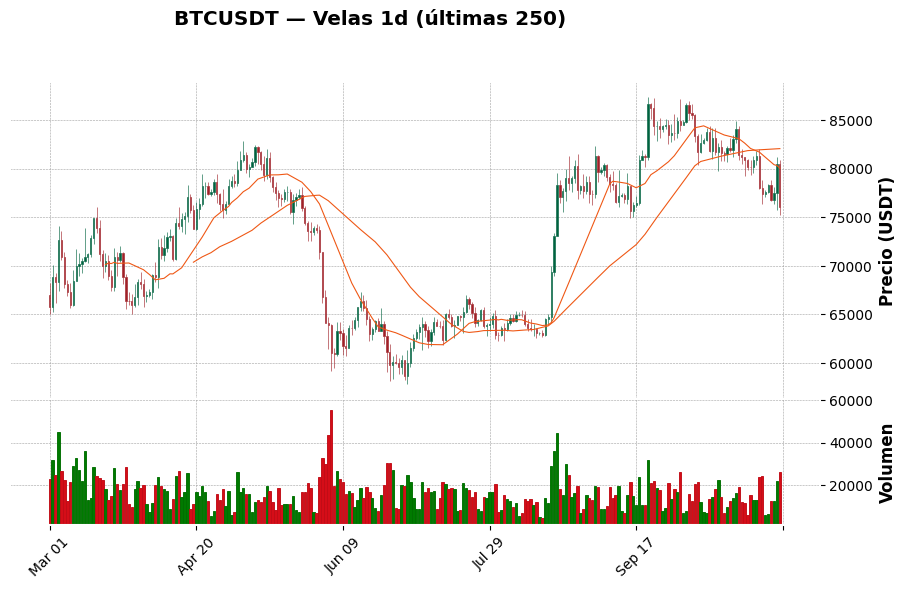

In [12]:
d_static = df_plot[["open", "high", "low", "close", "volume"]].tail(250).copy()
d_static.index = d_static.index.tz_localize(None)       # mplfinance trabaja mejor sin zona horaria

mpf.plot(
    d_static, type="candle", style="charles", mav=(20, 50), volume=True,
    title=f"{SYMBOL} — Velas {INTERVAL} (últimas {len(d_static)})",
    ylabel="Precio (USDT)", ylabel_lower="Volumen",
    figratio=(16, 9), figscale=1.1,
)

## 10. Features / indicadores técnicos

Primer paso hacia un dataset de trading: derivar variables de las velas. Están implementadas con `pandas`/`numpy` (sin librerías externas de análisis técnico) y sus ventanas se ajustan en la parte superior de la celda.

> **Las ventanas se miden en velas, no en días.** Una `SMA 20` en `1d` promedia 20 días; en `1h` promedia 20 horas.

| Grupo | Columnas |
|-------|----------|
| Precio previo y retornos | `prev_close`, `return`, `log_return`, `ret_5`, `ret_10`, `ret_20` |
| Forma de la vela | `body_pct`, `hl_range_pct`, `upper_wick_pct`, `lower_wick_pct`, `gap_pct` (apertura vs. cierre previo; en cripto 24/7 es casi siempre ≈ 0, por eso queda como dato informativo y no entra en `FEATURE_COLUMNS`) |
| Tendencia | `sma_7/20/50/200`, `close_to_sma_*` (distancia relativa del cierre a cada media) |
| Momentum | `rsi`, `macd`, `macd_signal`, `macd_hist`, `macd_hist_pct` |
| Volatilidad | `bb_upper/mid/lower`, `bb_pct_b`, `bb_width`, `atr`, `atr_pct`, `volatility` |
| Volumen / flujo | `volume_sma`, `volume_ratio`, `taker_buy_ratio` (compras agresivas / volumen), `trades_ratio` |

Las columnas en **precio absoluto** (`sma_*`, `bb_*`, `macd`, `atr`…) sirven para graficar. Para modelar suelen funcionar mejor las **relativas** (porcentajes y ratios), porque no dependen del nivel de precio; esas son las que reúne `FEATURE_COLUMNS`.

In [13]:
# --- Ventanas (en velas) -----------------------------------------------------
RET_WINDOWS = (5, 10, 20)
SMA_WINDOWS = (7, 20, 50, 200)
MACD_FAST, MACD_SLOW, MACD_SIGNAL = 12, 26, 9
RSI_WINDOW = 14
BB_WINDOW, BB_STD = 20, 2
ATR_WINDOW = 14
VOL_WINDOW = 20          # volatilidad = desviación estándar rodante del log-retorno
VOLUME_WINDOW = 20       # promedio rodante de volumen y de nº de trades


def add_features(data):
    """Agrega indicadores técnicos. Cada valor en la fila t usa solo datos hasta la vela t (sin mirar el futuro)."""
    f = data.copy()
    o, h, l, c, v = f["open"], f["high"], f["low"], f["close"], f["volume"]

    # Precio previo y retornos
    f["prev_close"] = c.shift(1)
    f["return"] = c / f["prev_close"] - 1
    f["log_return"] = np.log(c / f["prev_close"])
    for n in RET_WINDOWS:
        f[f"ret_{n}"] = c / c.shift(n) - 1

    # Forma de la vela
    f["body_pct"] = (c - o) / o
    f["hl_range_pct"] = (h - l) / c
    f["upper_wick_pct"] = (h - np.maximum(o, c)) / c
    f["lower_wick_pct"] = (np.minimum(o, c) - l) / c
    f["gap_pct"] = o / f["prev_close"] - 1

    # Medias móviles
    for n in SMA_WINDOWS:
        f[f"sma_{n}"] = c.rolling(n).mean()
        f[f"close_to_sma_{n}"] = c / f[f"sma_{n}"] - 1

    # MACD
    ema_fast = c.ewm(span=MACD_FAST, adjust=False, min_periods=MACD_FAST).mean()
    ema_slow = c.ewm(span=MACD_SLOW, adjust=False, min_periods=MACD_SLOW).mean()
    f["macd"] = ema_fast - ema_slow
    f["macd_signal"] = f["macd"].ewm(span=MACD_SIGNAL, adjust=False, min_periods=MACD_SIGNAL).mean()
    f["macd_hist"] = f["macd"] - f["macd_signal"]
    f["macd_hist_pct"] = f["macd_hist"] / c

    # RSI (suavizado de Wilder)
    delta = c.diff()
    avg_gain = delta.clip(lower=0).ewm(alpha=1 / RSI_WINDOW, adjust=False, min_periods=RSI_WINDOW).mean()
    avg_loss = (-delta.clip(upper=0)).ewm(alpha=1 / RSI_WINDOW, adjust=False, min_periods=RSI_WINDOW).mean()
    f["rsi"] = 100 - 100 / (1 + avg_gain / avg_loss)

    # Bandas de Bollinger
    mid = c.rolling(BB_WINDOW).mean()
    std = c.rolling(BB_WINDOW).std(ddof=0)
    f["bb_mid"] = mid
    f["bb_upper"] = mid + BB_STD * std
    f["bb_lower"] = mid - BB_STD * std
    f["bb_pct_b"] = (c - f["bb_lower"]) / (f["bb_upper"] - f["bb_lower"])
    f["bb_width"] = (f["bb_upper"] - f["bb_lower"]) / mid

    # ATR (suavizado de Wilder) y volatilidad
    true_range = pd.concat([h - l, (h - f["prev_close"]).abs(), (l - f["prev_close"]).abs()], axis=1).max(axis=1)
    f["atr"] = true_range.ewm(alpha=1 / ATR_WINDOW, adjust=False, min_periods=ATR_WINDOW).mean()
    f["atr_pct"] = f["atr"] / c
    f["volatility"] = f["log_return"].rolling(VOL_WINDOW).std()

    # Volumen y flujo de órdenes
    f["volume_sma"] = v.rolling(VOLUME_WINDOW).mean()
    f["volume_ratio"] = v / f["volume_sma"]
    f["taker_buy_ratio"] = (f["taker_buy_base"] / v).where(v > 0)
    f["trades_ratio"] = f["number_of_trades"] / f["number_of_trades"].rolling(VOLUME_WINDOW).mean()

    return f.replace([np.inf, -np.inf], np.nan)


# Features relativas (estacionarias) recomendadas como entrada de un modelo
FEATURE_COLUMNS = (
    ["return", "log_return"] + [f"ret_{n}" for n in RET_WINDOWS]
    + ["body_pct", "hl_range_pct", "upper_wick_pct", "lower_wick_pct"]   # gap_pct se omite: en cripto 24/7 es ≈ 0
    + [f"close_to_sma_{n}" for n in SMA_WINDOWS]
    + ["rsi", "macd_hist_pct", "bb_pct_b", "bb_width", "atr_pct", "volatility",
       "volume_ratio", "taker_buy_ratio", "trades_ratio"]
)

df_feat = add_features(df)
print(f"df_feat: {df_feat.shape[0]:,} filas x {df_feat.shape[1]} columnas "
      f"({len(FEATURE_COLUMNS)} features recomendadas en FEATURE_COLUMNS)")
display(df_feat[["open_time", "close", "prev_close", "return", "sma_20", "rsi", "macd_hist", "bb_pct_b", "atr_pct"]].tail())

df_feat: 3,368 filas x 49 columnas (22 features recomendadas en FEATURE_COLUMNS)


,open_time,close,prev_close,return,sma_20,rsi,macd_hist,bb_pct_b,atr_pct
3363,2026-11-01 00:00:00+00:00,78354.00,77582.02,0.009951,80936.3935,39.435019,-451.766458,0.143998,0.024958
3364,2026-11-02 00:00:00+00:00,76816.00,78354.00,-0.019629,80618.7435,34.841278,-480.015608,0.011499,0.025660
3365,2026-11-03 00:00:00+00:00,77453.86,76816.00,0.008304,80407.3360,38.063707,-424.874211,0.139155,0.025175
3366,2026-11-04 00:00:00+00:00,80504.01,77453.86,0.039380,80320.2400,50.635704,-165.440750,0.522940,0.027335
3367,2026-11-05 00:00:00+00:00,76088.01,80504.01,-0.054854,80043.8585,38.462836,-267.656090,0.046050,0.032216


## 11. Gráficos con indicadores y análisis

Los gráficos de **precio** usan las últimas `PLOT_LAST_N_CANDLES` velas; los de **distribución, drawdown y heatmap mensual** usan el dataset completo, porque son estadísticas del histórico.

### 11.1 Dashboard: velas + Bollinger + SMA + volumen + RSI + MACD

In [14]:
def plot_dashboard(d, title):
    fig = make_subplots(
        rows=4, cols=1, shared_xaxes=True, vertical_spacing=0.025,
        row_heights=[0.52, 0.12, 0.18, 0.18],
        subplot_titles=(title, "Volumen", f"RSI ({RSI_WINDOW})", f"MACD ({MACD_FAST},{MACD_SLOW},{MACD_SIGNAL})"),
    )

    # Precio: banda de Bollinger (se dibuja primero para quedar detrás de las velas)
    fig.add_trace(go.Scatter(x=d.index, y=d["bb_lower"], line=dict(width=0),
                             showlegend=False, hoverinfo="skip"), row=1, col=1)
    fig.add_trace(go.Scatter(x=d.index, y=d["bb_upper"], line=dict(width=0), fill="tonexty",
                             fillcolor="rgba(120,144,156,0.18)", name=f"Bollinger ({BB_WINDOW},{BB_STD})",
                             hoverinfo="skip"), row=1, col=1)
    fig.add_trace(go.Candlestick(
        x=d.index, open=d["open"], high=d["high"], low=d["low"], close=d["close"], name="Precio",
        increasing_line_color=COLOR_UP, decreasing_line_color=COLOR_DOWN,
        hovertext=candle_hovertext(d), hoverinfo="text"), row=1, col=1)
    fig.add_trace(go.Scatter(x=d.index, y=d["sma_20"], name="SMA 20", line=dict(color="#ffb300", width=1.2),
                             hovertemplate="SMA 20  %{y:,.2f}<extra></extra>"), row=1, col=1)
    fig.add_trace(go.Scatter(x=d.index, y=d["sma_50"], name="SMA 50", line=dict(color="#42a5f5", width=1.2),
                             hovertemplate="SMA 50  %{y:,.2f}<extra></extra>"), row=1, col=1)

    # Volumen
    vol_colors = [COLOR_UP if c >= o else COLOR_DOWN for o, c in zip(d["open"], d["close"])]
    fig.add_trace(go.Bar(x=d.index, y=d["volume"], marker_color=vol_colors, name="Volumen", showlegend=False,
                         hovertemplate="Vol  %{y:,.2f}<extra></extra>"), row=2, col=1)

    # RSI
    fig.add_trace(go.Scatter(x=d.index, y=d["rsi"], name="RSI", line=dict(color="#ab47bc", width=1.3),
                             hovertemplate="RSI  %{y:.1f}<extra></extra>"), row=3, col=1)
    fig.add_hrect(y0=30, y1=70, fillcolor="rgba(171,71,188,0.08)", line_width=0, row=3, col=1)
    for lvl in (30, 70):
        fig.add_hline(y=lvl, line_dash="dot", line_color="#758696", line_width=1, row=3, col=1)

    # MACD
    hist_colors = [COLOR_UP if x >= 0 else COLOR_DOWN for x in d["macd_hist"].fillna(0)]
    fig.add_trace(go.Bar(x=d.index, y=d["macd_hist"], marker_color=hist_colors, name="Histograma",
                         showlegend=False, hovertemplate="Hist  %{y:,.2f}<extra></extra>"), row=4, col=1)
    fig.add_trace(go.Scatter(x=d.index, y=d["macd"], name="MACD", line=dict(color="#42a5f5", width=1.2),
                             hovertemplate="MACD  %{y:,.2f}<extra></extra>"), row=4, col=1)
    fig.add_trace(go.Scatter(x=d.index, y=d["macd_signal"], name="Señal", line=dict(color="#ffb300", width=1.2),
                             hovertemplate="Señal  %{y:,.2f}<extra></extra>"), row=4, col=1)

    fig.update_layout(
        height=950, template=PLOT_TEMPLATE, hovermode="x unified", xaxis_rangeslider_visible=False,
        hoverlabel=dict(bgcolor="#131722", bordercolor="#2a2e39", align="left",
                        font=dict(family="Consolas, Menlo, monospace", size=12, color="#d1d4dc")),
        legend=dict(orientation="h", y=1.04, x=0), margin=dict(l=40, r=40, t=90, b=40),
    )
    fig.update_yaxes(title_text="USDT", row=1, col=1)
    fig.update_yaxes(range=[0, 100], row=3, col=1)
    fig.update_xaxes(rangeselector=RANGE_SELECTOR, row=1, col=1)
    fig.update_xaxes(showspikes=True, spikemode="across", spikesnap="cursor",
                     spikecolor="#758696", spikethickness=1, spikedash="dot")
    return fig


d_dash = get_plot_df(df_feat)
fig_dash = plot_dashboard(d_dash, f"{SYMBOL} — {INTERVAL} con indicadores ({len(d_dash):,} velas)")
show_fig(fig_dash, "dashboard")

### 11.2 Distribución de retornos

Los retornos financieros no son normales: tienen **colas gruesas** (valores extremos más frecuentes de lo esperado). La *curtosis en exceso* positiva lo cuantifica (0 sería una normal).

In [15]:
ret = df_feat["log_return"].dropna() * 100

fig_hist = go.Figure(go.Histogram(x=ret, nbinsx=120, marker_color=COLOR_UP, opacity=0.85,
                                  hovertemplate="Retorno %{x:.2f}%<br>Frecuencia %{y}<extra></extra>"))
fig_hist.add_vline(x=ret.mean(), line_dash="dash", line_color="#ffb300",
                   annotation_text=f"media {ret.mean():.3f}%", annotation_position="top")
fig_hist.update_layout(
    title=(f"{SYMBOL} — Distribución del retorno logarítmico por vela ({INTERVAL})<br>"
           f"<sup>σ = {ret.std():.2f}% | asimetría = {ret.skew():.2f} | curtosis en exceso = {ret.kurt():.1f} | n = {len(ret):,}</sup>"),
    template=PLOT_TEMPLATE, height=450, bargap=0.02, margin=dict(l=40, r=40, t=80, b=40),
)
fig_hist.update_xaxes(title_text="Retorno por vela (%)")
fig_hist.update_yaxes(title_text="Frecuencia")
show_fig(fig_hist, "returns_hist")

### 11.3 Volatilidad rodante y drawdown

In [16]:
d_full = df_feat.set_index("open_time")

fig_risk = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08,
                         subplot_titles=(f"Volatilidad rodante ({VOL_WINDOW} velas, desv. estándar del log-retorno)",
                                         "Drawdown desde el máximo previo"))

fig_risk.add_trace(go.Scatter(x=d_full.index, y=d_full["volatility"] * 100, name="Volatilidad",
                              line=dict(color="#ffb300", width=1.2),
                              hovertemplate="Volatilidad  %{y:.2f}%<extra></extra>"), row=1, col=1)

drawdown = (d_full["close"] / d_full["close"].cummax() - 1) * 100
fig_risk.add_trace(go.Scatter(x=d_full.index, y=drawdown, name="Drawdown", fill="tozeroy",
                              line=dict(color=COLOR_DOWN, width=1), fillcolor="rgba(239,83,80,0.30)",
                              hovertemplate="Drawdown  %{y:.1f}%<extra></extra>"), row=2, col=1)

fig_risk.update_layout(
    title=f"{SYMBOL} — Riesgo ({INTERVAL}) | drawdown máximo: {drawdown.min():.1f}%",
    template=PLOT_TEMPLATE, height=620, hovermode="x unified", showlegend=False,
    margin=dict(l=40, r=40, t=80, b=40),
)
fig_risk.update_yaxes(title_text="% por vela", row=1, col=1)
fig_risk.update_yaxes(title_text="%", row=2, col=1)
fig_risk.update_xaxes(rangeselector=RANGE_SELECTOR, row=1, col=1)
show_fig(fig_risk, "risk")

### 11.4 Heatmap de retornos mensuales

Retorno de cada mes calculado entre cierres de fin de mes. El **mes en curso** (el último) es parcial.

In [17]:
monthly = d_full["close"].resample("MS").last().pct_change().dropna() * 100

if monthly.empty:
    print("No hay suficientes meses para el heatmap (se necesitan al menos 2 meses de datos).")
else:
    tbl = monthly.to_frame("ret")
    tbl["year"], tbl["month"] = tbl.index.year, tbl.index.month
    pivot = tbl.pivot(index="year", columns="month", values="ret").reindex(columns=range(1, 13))

    meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
    labels = np.where(pivot.isna(), "", pivot.round(1).astype(str) + "%")

    fig_heat = go.Figure(go.Heatmap(
        z=pivot.values, x=meses, y=pivot.index.astype(str), text=labels, texttemplate="%{text}",
        colorscale="RdYlGn", zmid=0, colorbar=dict(title="%"),
        hovertemplate="%{y} %{x}: %{z:.2f}%<extra></extra>",
    ))
    fig_heat.update_layout(
        title=f"{SYMBOL} — Retorno mensual (%)", template=PLOT_TEMPLATE,
        height=max(300, 60 * len(pivot) + 120), margin=dict(l=40, r=40, t=60, b=40),
    )
    fig_heat.update_yaxes(autorange="reversed", type="category")
    show_fig(fig_heat, "monthly_returns")

## 12. Target, limpieza de filas y split temporal

**Target (lo que se quiere predecir)**, calculado mirando `TARGET_HORIZON` velas hacia adelante:

- `target_return`: retorno futuro `close(t+H) / close(t) − 1` (regresión).
- `target_up`: `1` si ese retorno es positivo, `0` si no (clasificación).

**Cuidados importantes**

1. **Nunca uses `target_*` como feature:** contienen información del futuro.
2. Las primeras filas quedan sin valor por el *warm-up* de los indicadores (la `SMA 200` necesita 200 velas) y las últimas `TARGET_HORIZON` filas no tienen target. Se eliminan.
3. **El split es cronológico** (train → val → test), sin mezclar fechas: mezclarlas filtraría información del futuro hacia el entrenamiento.
4. Cualquier escalado o normalización debe ajustarse **solo con `train`** y luego aplicarse a `val` y `test`.
5. Una vela `t` solo se conoce completa en su `close_time`: en un backtest, la operación se simula a partir de la **siguiente** vela.

In [18]:
def add_target(data, horizon=TARGET_HORIZON):
    f = data.copy()
    f["target_return"] = f["close"].shift(-horizon) / f["close"] - 1
    f["target_up"] = (f["target_return"] > 0).astype("Int64").where(f["target_return"].notna())
    return f


df_feat = add_target(df_feat)

# Filas utilizables: todas las features y el target presentes
needed = FEATURE_COLUMNS + ["target_return", "target_up"]
df_model = df_feat.dropna(subset=needed).reset_index(drop=True)

if df_model.empty:
    raise ValueError(
        f"Quedaron 0 filas utilizables ({len(df_feat)} velas). Con SMA_WINDOWS={SMA_WINDOWS} y "
        f"TARGET_HORIZON={TARGET_HORIZON} hacen falta más velas: amplía el rango de fechas o reduce las ventanas."
    )

print(f"Filas totales: {len(df_feat):,} | utilizables: {len(df_model):,} "
      f"(descartadas: {len(df_feat) - len(df_model):,} por warm-up de indicadores y target futuro)")

# Split cronológico
n = len(df_model)
i_train = int(n * TRAIN_FRAC)
i_val = int(n * (TRAIN_FRAC + VAL_FRAC))
df_model["split"] = ["train"] * i_train + ["val"] * (i_val - i_train) + ["test"] * (n - i_val)

summary = df_model.groupby("split", sort=False).agg(
    filas=("open_time", "size"),
    desde=("open_time", "min"),
    hasta=("open_time", "max"),
    pct_velas_alcistas=("target_up", lambda s: round(float(s.astype(float).mean()) * 100, 1)),
    retorno_futuro_medio_pct=("target_return", lambda s: round(float(s.mean()) * 100, 3)),
)
display(summary)

Filas totales: 3,368 | utilizables: 3,168 (descartadas: 200 por warm-up de indicadores y target futuro)


,filas,desde,hasta,pct_velas_alcistas,retorno_futuro_medio_pct
split,,,,,
train,2217,2018-03-04 00:00:00+00:00,2024-03-28 00:00:00+00:00,51.2,0.146
val,475,2024-03-29 00:00:00+00:00,2025-07-16 00:00:00+00:00,51.6,0.144
test,476,2025-07-17 00:00:00+00:00,2026-11-04 00:00:00+00:00,48.1,-0.070


### 12.1 Relación entre features y target (solo con `train`)

Se calcula únicamente sobre `train` para no "espiar" `val` ni `test`. En mercados financieros las correlaciones con el retorno futuro suelen ser **muy cercanas a cero**: es normal y es una buena referencia de lo difícil que es predecir.

In [19]:
train = df_model[df_model["split"] == "train"]

# Una feature constante no tiene correlación definida: se excluye del análisis
corr_cols = [c for c in FEATURE_COLUMNS if train[c].std() > 0]
if len(corr_cols) < len(FEATURE_COLUMNS):
    print("Features constantes en train (excluidas de las correlaciones):", sorted(set(FEATURE_COLUMNS) - set(corr_cols)))

# Barras: correlación de cada feature con el retorno futuro
corr_target = train[corr_cols].corrwith(train["target_return"]).sort_values()

fig_bar = go.Figure(go.Bar(
    x=corr_target.values, y=corr_target.index, orientation="h",
    marker_color=[COLOR_UP if x >= 0 else COLOR_DOWN for x in corr_target.values],
    hovertemplate="%{y}: %{x:.3f}<extra></extra>",
))
fig_bar.update_layout(
    title=f"Correlación de cada feature con target_return (train, horizonte = {TARGET_HORIZON} vela/s)",
    template=PLOT_TEMPLATE, height=max(420, 22 * len(corr_target) + 120), margin=dict(l=40, r=40, t=60, b=40),
)
fig_bar.update_xaxes(title_text="Correlación de Pearson")
show_fig(fig_bar, "corr_target")

# Heatmap: correlación entre features (para detectar redundancia)
corr = train[corr_cols].corr()
fig_corr = go.Figure(go.Heatmap(
    z=corr.values, x=corr.columns, y=corr.index, zmin=-1, zmax=1, zmid=0, colorscale="RdBu",
    text=corr.round(2).values, texttemplate="%{text}", textfont=dict(size=8),
    hovertemplate="%{y} vs %{x}: %{z:.2f}<extra></extra>",
))
fig_corr.update_layout(
    title="Correlación entre features (train)", template=PLOT_TEMPLATE, height=820,
    margin=dict(l=40, r=40, t=60, b=40),
)
fig_corr.update_yaxes(autorange="reversed")
show_fig(fig_corr, "corr_matrix")

## 13. Exportar el dataset de trading

Se exporta `df_model`: velas + indicadores + `target_return` + `target_up` + columna `split`.
La hoja `info` del Excel documenta qué columnas son features recomendadas, el horizonte del target y las ventanas usadas.

In [20]:
info_features = {
    **DATASET_INFO,
    "filas": len(df_model),
    "tipo_dataset": "features + target (listo para modelar)",
    "primera_vela_utc": str(df_model["open_time"].min()),
    "ultima_vela_utc": str(df_model["open_time"].max()),
    "target_horizonte_velas": TARGET_HORIZON,
    "targets": "target_return (regresion), target_up (clasificacion 0/1)",
    "split": f"cronologico train={TRAIN_FRAC:.0%} val={VAL_FRAC:.0%} test={1 - TRAIN_FRAC - VAL_FRAC:.0%}",
    "ventanas": (f"SMA={SMA_WINDOWS}, RET={RET_WINDOWS}, MACD=({MACD_FAST},{MACD_SLOW},{MACD_SIGNAL}), "
                 f"RSI={RSI_WINDOW}, BB=({BB_WINDOW},{BB_STD}), ATR={ATR_WINDOW}, VOL={VOL_WINDOW}, VOLUMEN={VOLUME_WINDOW}"),
    "features_recomendadas": ", ".join(FEATURE_COLUMNS),
    "aviso": "No usar target_* como feature. Escalar/normalizar solo con train.",
}

paths_features = export_dataset(df_model, f"{BASE_NAME}_features", info=info_features)
df_model.head()

Guardado: datasets/dataset_BTCUSDT_1d_features.csv  (2.76 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Guardado: datasets/dataset_BTCUSDT_1d_features.xlsx  (1.79 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,symbol,interval,open_time,open,high,low,close,volume,close_time,quote_asset_volume,number_of_trades,taker_buy_base,taker_buy_quote,prev_close,return,log_return,ret_5,ret_10,ret_20,body_pct,hl_range_pct,upper_wick_pct,lower_wick_pct,gap_pct,sma_7,close_to_sma_7,sma_20,close_to_sma_20,sma_50,close_to_sma_50,sma_200,close_to_sma_200,macd,macd_signal,macd_hist,macd_hist_pct,rsi,bb_mid,bb_upper,bb_lower,bb_pct_b,bb_width,atr,atr_pct,volatility,volume_sma,volume_ratio,taker_buy_ratio,trades_ratio,target_return,target_up,split
0,BTCUSDT,1d,2018-03-04 00:00:00+00:00,11464.47,11565.0,11050.02,11515.00,17295.918653,2018-03-04 23:59:59.999000+00:00,1.948496e+08,168359,8197.401595,9.243701e+07,11464.48,0.004407,0.004397,0.089503,0.173678,0.293384,0.004408,0.044723,0.004342,0.035992,-8.722594e-07,10879.754286,0.058388,10387.4700,0.108547,10267.6060,0.121488,8756.49030,0.315025,288.042111,87.794088,200.248023,0.017390,59.630728,10387.4700,11861.512259,8913.427741,0.882462,0.283812,909.874009,0.079016,0.051823,40223.467409,0.429996,0.473950,0.456700,-0.005297,0,train
1,BTCUSDT,1d,2018-03-05 00:00:00+00:00,11515.00,11710.0,11415.01,11454.00,15144.231063,2018-03-05 23:59:59.999000+00:00,1.748670e+08,164318,7668.823714,8.858899e+07,11515.00,-0.005297,-0.005312,0.109157,0.130585,0.341234,-0.005297,0.025754,0.017025,0.003404,0.000000e+00,11041.182857,0.037389,10533.1750,0.087421,10227.1862,0.119956,8792.33490,0.302726,327.683844,135.772039,191.911804,0.016755,59.007447,10533.1750,11810.936738,9255.413262,0.860327,0.242617,865.953723,0.075603,0.050430,39207.930314,0.386254,0.506386,0.460579,-0.064390,0,train
2,BTCUSDT,1d,2018-03-06 00:00:00+00:00,11455.00,11455.0,10555.48,10716.48,29515.572363,2018-03-06 23:59:59.999000+00:00,3.238422e+08,250306,13482.297196,1.478741e+08,11454.00,-0.064390,-0.066556,-0.018637,0.105417,0.134020,-0.064471,0.083938,0.000000,0.015024,8.730574e-05,11062.245714,-0.031256,10596.4995,0.011323,10170.7172,0.053660,8825.37545,0.214280,296.174388,167.852509,128.321879,0.011974,51.938836,10596.4995,11774.929509,9418.069491,0.550907,0.222419,868.351314,0.081030,0.049212,38643.111289,0.763799,0.456786,0.728620,-0.075256,0,train
3,BTCUSDT,1d,2018-03-07 00:00:00+00:00,10716.48,10899.0,9389.31,9910.00,50647.671080,2018-03-07 23:59:59.999000+00:00,5.148080e+08,396721,24022.451231,2.441648e+08,10716.48,-0.075256,-0.078238,-0.102274,0.033368,-0.009009,-0.075256,0.152340,0.018418,0.052542,0.000000e+00,11002.708571,-0.099313,10591.9950,-0.064388,10150.9172,-0.023734,8854.22555,0.119240,203.777699,175.037547,28.740152,0.002900,45.517698,10591.9950,11780.158111,9403.831889,0.213004,0.224351,914.161220,0.092246,0.051156,38554.115007,1.313677,0.474305,1.191523,-0.064416,0,train
4,BTCUSDT,1d,2018-03-08 00:00:00+00:00,9910.00,10099.0,9060.00,9271.64,41109.473226,2018-03-08 23:59:59.999000+00:00,3.946413e+08,336514,20257.455838,1.946087e+08,9910.00,-0.064416,-0.066584,-0.191273,-0.101933,-0.087435,-0.064416,0.112062,0.020385,0.022827,0.000000e+00,10767.228571,-0.138902,10547.5780,-0.120970,10116.5742,-0.083520,8880.15230,0.044086,78.141573,155.658352,-77.516779,-0.008361,41.178160,10547.5780,11857.226873,9237.929127,0.012870,0.248332,923.078276,0.099559,0.053059,38701.528370,1.062218,0.492769,1.021246,-0.004815,0,train


## Apéndice (opcional) — Exploración de la API

Estos endpoints **no son necesarios para construir el dataset de velas**; vienen del notebook original de peticiones REST y se conservan como referencia o como punto de partida si luego quieres sumar más fuentes (order book, trades, etc.).
Se ejecutan contra la misma `BASE_URL_USED` ya resuelta.

### A.1 Conectividad, hora del servidor y límites del exchange

In [21]:
# /ping y /time
api_get("ping", base_url=BASE_URL_USED)
t0 = now_ms()
server_ms = api_get("time", base_url=BASE_URL_USED)["serverTime"]
t1 = now_ms()
display(pd.DataFrame([{
    "ping": "OK",
    "servidor_utc": pd.to_datetime(server_ms, unit="ms", utc=True),
    "latencia_ms": t1 - t0,
    "desfase_reloj_vs_servidor_ms": round(server_ms - (t0 + t1) / 2),
}]))

# /exchangeInfo del símbolo elegido (confirma que existe y muestra sus filtros de trading)
ex = api_get("exchangeInfo", {"symbol": SYMBOL}, base_url=BASE_URL_USED)
sym = ex["symbols"][0]
print(f"{sym['symbol']}: estado={sym['status']} | base={sym['baseAsset']} | cotización={sym['quoteAsset']}")
print("\nFiltros del símbolo (tick size, step size, notional mínimo, etc.):")
display(pd.DataFrame(sym["filters"]))
print("Rate limits del exchange:")
display(pd.DataFrame(ex["rateLimits"]))

,ping,servidor_utc,latencia_ms,desfase_reloj_vs_servidor_ms
0,OK,2026-11-06 02:12:31.648000+00:00,642,240


BTCUSDT: estado=TRADING | base=BTC | cotización=USDT

Filtros del símbolo (tick size, step size, notional mínimo, etc.):


,filterType,minPrice,maxPrice,tickSize,minQty,maxQty,stepSize,limit,minTrailingAboveDelta,maxTrailingAboveDelta,minTrailingBelowDelta,maxTrailingBelowDelta,bidMultiplierUp,bidMultiplierDown,askMultiplierUp,askMultiplierDown,avgPriceMins,minNotional,applyMinToMarket,maxNotional,applyMaxToMarket,maxNumOrders,maxNumOrderLists,maxNumAlgoOrders,maxNumOrderAmends
0,PRICE_FILTER,0.01000000,1000000.00000000,0.01000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LOT_SIZE,NaN,NaN,NaN,0.00001000,9000.00000000,0.00001000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ICEBERG_PARTS,NaN,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,MARKET_LOT_SIZE,NaN,NaN,NaN,0.00000000,107.45010962,0.00000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,TRAILING_DELTA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,2000.0,10.0,2000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,PERCENT_PRICE_BY_SIDE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.2,0.5,2,0.8,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NOTIONAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,5.00000000,True,9000000.00000000,False,NaN,NaN,NaN,NaN
7,MAX_NUM_ORDERS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,200.0,NaN,NaN,NaN
8,MAX_NUM_ORDER_LISTS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.0,NaN,NaN
9,MAX_NUM_ALGO_ORDERS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN


Rate limits del exchange:


,rateLimitType,interval,intervalNum,limit
0,REQUEST_WEIGHT,MINUTE,1,6000
1,ORDERS,SECOND,10,100
2,ORDERS,DAY,1,200000
3,RAW_REQUESTS,MINUTE,5,300000


### A.2 Foto del mercado: order book, trades recientes y ticker 24 h

In [22]:
# Order book (/depth)
depth = api_get("depth", {"symbol": SYMBOL, "limit": 100}, base_url=BASE_URL_USED)
bids = pd.DataFrame(depth["bids"], columns=["price", "quantity"], dtype=float)
asks = pd.DataFrame(depth["asks"], columns=["price", "quantity"], dtype=float)
spread = asks["price"].iloc[0] - bids["price"].iloc[0]
print(f"Mejor bid: {bids['price'].iloc[0]:,.4f} | mejor ask: {asks['price'].iloc[0]:,.4f} | "
      f"spread: {spread:,.4f} ({spread / bids['price'].iloc[0] * 100:.4f}%)")
print("\nTop 5 bids (compra):"); display(bids.head())
print("Top 5 asks (venta):");  display(asks.head())

# Trades recientes (/trades)
df_trades = pd.DataFrame(api_get("trades", {"symbol": SYMBOL, "limit": 50}, base_url=BASE_URL_USED))
df_trades["time"] = pd.to_datetime(df_trades["time"], unit="ms", utc=True)
print("\nTrades recientes:"); display(df_trades.head())

# Ticker de las últimas 24 h (/ticker/24hr)
stats_24h = api_get("ticker/24hr", {"symbol": SYMBOL}, base_url=BASE_URL_USED)
print("\nEstadísticas 24 h:"); display(pd.Series(stats_24h).to_frame("valor"))

Mejor bid: 76,188.0000 | mejor ask: 76,188.0100 | spread: 0.0100 (0.0000%)

Top 5 bids (compra):


,price,quantity
0,76188.00,8.97520
1,76187.49,3.15115
2,76186.78,0.01864
3,76186.63,0.00007
4,76186.50,0.00007


Top 5 asks (venta):


,price,quantity
0,76188.01,0.12750
1,76188.02,0.00070
2,76189.01,0.00033
3,76189.54,0.00007
4,76190.00,0.00014



Trades recientes:


,id,price,qty,quoteQty,time,isBuyerMaker,isBestMatch
0,6826131322,76187.50000000,0.00007000,5.33312500,2026-11-06 02:12:32.672000+00:00,False,True
1,6826131323,76187.50000000,0.00007000,5.33312500,2026-11-06 02:12:32.672000+00:00,False,True
2,6826131324,76187.50000000,0.00007000,5.33312500,2026-11-06 02:12:32.672000+00:00,False,True
3,6826131325,76187.50000000,0.00007000,5.33312500,2026-11-06 02:12:32.672000+00:00,False,True
4,6826131326,76187.50000000,0.00007000,5.33312500,2026-11-06 02:12:32.672000+00:00,False,True



Estadísticas 24 h:


,valor
symbol,BTCUSDT
priceChange,-4624.00000000
priceChangePercent,-5.722
weightedAvgPrice,77474.24262043
prevClosePrice,80812.01000000
lastPrice,76188.00000000
lastQty,0.00070000
bidPrice,76188.00000000
bidQty,9.14245000
askPrice,76188.01000000


## Siguientes pasos sugeridos

- **Varios pares en un solo dataset:** repetir la descarga por símbolo y concatenar los DataFrames (`symbol` ya es una columna). Calcula los features **por símbolo** (`groupby("symbol")`) para que las ventanas no se mezclen entre pares.
- **Actualización incremental:** guardar el último `open_time` y descargar solo las velas nuevas en lugar de bajar todo el histórico de nuevo.
- **Más fuentes de datos:** *funding rate*, *open interest* y *long/short ratio* están en la API de futuros de Binance (`fapi.binance.com`); suelen aportar más señal que el precio solo.
- **Otros targets:** retorno ajustado por volatilidad, *triple-barrier* (take profit / stop loss / tiempo) o umbral mínimo de movimiento para ignorar el ruido.
- **Validación:** *walk-forward* (re-entrenar y validar en ventanas sucesivas) y siempre incluir **comisiones y deslizamiento** al simular una estrategia.
- **Formato de almacenamiento:** para datasets grandes (intervalos de minutos), `parquet` pesa y carga mucho mejor que CSV/Excel.